# Conjunto A — cancelamento tardio e decisão por reserva

## Cinco decisões, antes de qualquer import

| Decisão | Definição |
|---|---|
| Unidade de análise | Uma reserva do City Hotel; a decisão se refere à primeira noite |
| Instante da decisão | Início do dia de chegada, após fechar os registros da véspera |
| Janela de observação | Atributos disponíveis até a véspera e histórico anterior; nenhum status final como preditor |
| Janela de desempenho | Cancelamento ou não comparecimento no dia de chegada |
| População elegível | Reservas feitas antes da chegada, com 1 a 14 noites planejadas e ainda ativas ao fechar a véspera |

## Negócio, dois custos e hipóteses

Você quer decidir se oferece novamente a primeira noite de uma reserva ativa,
apostando que o titular não chegará. `y=1` significa cancelamento na chegada ou
no-show. Cancelamentos já conhecidos antes disso saem da população: não há
incerteza a prever nesses casos.

| Ação e desfecho | Titular chega (`y=0`) | Titular não chega (`y=1`) |
|---|---:|---:|
| Não revender | R$ 0 de perda incremental | R$ 400: oportunidade perdida |
| Revender | R$ 1.200: acomodação e compensação | R$ 0 de perda incremental |

São **custos hipotéticos em reais**, inspirados no enunciado, não preços
observados em Portugal. A simulação pressupõe procura substituta suficiente,
uma reserva representando uma vaga de primeira noite e os demais custos iguais.
Não temos capacidade real do hotel, inventário por tipo de quarto, penalidades
cobradas, efetividade da revenda ou receita contrafactual. Portanto avaliamos
**perda incremental sob hipóteses**, não lucro real nem autorização operacional
para praticar overbooking. As demais noites não fazem parte desta perda.

Revender custa em esperança `1.200 × (1-p)`; não revender custa `400 × p`.
Revenda se `p ≥ 1.200 / (1.200 + 400) = 0,75` (no empate, as ações equivalem).
O custo alto de prejudicar quem chega exige uma probabilidade elevada.

## Fontes e execução

- [Enunciado](../fontes/TRABALHO_extraclasse.pdf).
- Antonio, Almeida e Nunes (2019), [artigo original](https://doi.org/10.1016/j.dib.2018.11.126).
- [TidyTuesday, 11/02/2020](https://github.com/rfordatascience/tidytuesday/tree/main/data/2020/2020-02-11), espelho dos dados e dicionário.
- Cópias e metadados em `../fontes/` e `../dados/proveniencia.json`.
- Rotinas compartilhadas auditáveis: [metodo.py](../src/metodo.py). Não é necessário executar outro notebook antes deste.
- Dependências: `../requirements.txt`; instruções locais: `../COMO_EXECUTAR.md`.

O artigo é distribuído sob CC BY. O espelho atribui os dados aos autores;
não presumimos uma licença CC0 independente. Consulte a documentação preservada
para atribuição e condições. Houve uso de IA; a especificação e suas revisões estão
no `.md` ao lado deste notebook.

## 1. Ler uma cópia verificável

A mesma função de população será usada nos dois conjuntos. Ela verifica o hash e interrompe a execução se as datas contradisserem o embargo.

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

candidatas = [Path.cwd(), *Path.cwd().parents]
RAIZ = next(p for p in candidatas if (p / 'src/metodo.py').exists())
sys.path.insert(0, str(RAIZ / 'src'))
from metodo import *

plt.rcParams.update({'figure.figsize': (11, 4), 'axes.grid': True, 'grid.alpha': 0.2})
pd.set_option('display.max_columns', 20)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')
bruto, dados, filtros = carregar_dados()
serie = construir_serie(dados)

display(pd.Series(json.loads((RAIZ / 'dados/proveniencia.json').read_text())))
display(filtros)

fonte_download            https://raw.githubusercontent.com/rfordatascie...
fonte_documentacao        https://github.com/rfordatascience/tidytuesday...
artigo_original                   https://doi.org/10.1016/j.dib.2018.11.126
data_obtencao_local                                              2026-11-17
sha256                    7c2ae42a7353905ea136e5c2287f17c92c5435826598bf...
bytes                                                              16855599
linhas                                                               119390
licenca                   Artigo original: CC BY, conforme o próprio PDF...
documentos_preservados    [{'arquivo': 'fontes/TRABALHO_extraclasse.pdf'...
dtype: object

,etapa,antes,depois,excluidas
0,Arquivo integral,119390,119390,0
1,Somente City Hotel,119390,79330,40060
2,Criada antes do dia da chegada,79330,76221,3109
3,Estadia planejada entre 1 e 14 noites,76221,75940,281
4,Ativa no fim da véspera,75940,44393,31547


**Leitura:** a tabela de filtros torna os descartes visíveis. O hash identifica a cópia utilizada. Se mudar, você deve refazer a auditoria, não ignorar o erro.

## 2. A base escolhida e as alternativas

Uma base grande pode ficar curta depois da agregação. Também precisamos de um alvo que possa ser reconstruído sem revelar o futuro.

In [2]:
resumo = pd.DataFrame([
    {'medida': 'Reservas no arquivo', 'valor': len(bruto)},
    {'medida': 'Reservas elegíveis', 'valor': len(dados)},
    {'medida': 'Cancelamentos tardios/no-shows', 'valor': int(dados.is_canceled.sum())},
    {'medida': 'Dias no calendário', 'valor': len(serie)},
    {'medida': 'Dias sem reserva elegível', 'valor': int(serie.exposicao.eq(0).sum())},
    {'medida': 'Taxa positiva', 'valor': dados.is_canceled.mean()},
])
display(resumo)
display(dados.groupby('reservation_status').agg(reservas=('id_linha','size')))

,medida,valor
0,Reservas no arquivo,"119,390.0000"
1,Reservas elegíveis,"44,393.0000"
2,Cancelamentos tardios/no-shows,"1,155.0000"
3,Dias no calendário,793.0000
4,Dias sem reserva elegível,6.0000
5,Taxa positiva,0.0260


,reservas
reservation_status,
Canceled,345
Check-Out,43238
No-Show,810


**Leitura:** o alvo não inclui cancelamentos conhecidos antes da chegada.
O nome `is_canceled` é mantido da fonte, mas na população filtrada ele significa
somente a incerteza restante na véspera. Uma taxa pequena torna acurácia uma
métrica insuficiente e pode justificar não revender nenhuma reserva.

Hotel Booking Demand foi escolhida pela ligação com a decisão do enunciado
e por permitir auditar a data do cancelamento. Online Retail II permaneceu
como alternativa: identificar faturas C não basta para prever a devolução
da venda original. Voos também serviria, mas exigiria outro recorte operacional
e outros custos. Elas não foram baixadas nem declaradas inviáveis; foram
preteridas na triagem documental. As bases da disciplina não são utilizadas.

## 3. Duplicatas e completude

A anonimização pode tornar duas reservas distintas idênticas. Sem chave da reserva, deduplicar pode apagar demanda real. Vamos contar e preservar essas linhas.

In [3]:
colunas_fonte = [c for c in bruto.columns if c not in [
    'id_linha','data_chegada','data_status','data_criacao_aproximada',
    'noites','dia_semana','mes','data_rotulo']]
print('Linhas integralmente idênticas adicionais:', int(bruto.duplicated(colunas_fonte).sum()))
print('Antes/depois da decisão de preservar:', len(bruto), len(bruto))
display(bruto[colunas_fonte].isin(['NULL','NA','']).sum().sort_values(ascending=False).head(10))
display(serie.loc[serie.exposicao.eq(0), ['exposicao','cancelamentos']])

Linhas integralmente idênticas adicionais: 31994
Antes/depois da decisão de preservar: 119390 119390


company                   112593
agent                      16340
country                      488
children                       4
reserved_room_type             0
assigned_room_type             0
booking_changes                0
deposit_type                   0
hotel                          0
previous_cancellations         0
dtype: int64

,exposicao,cancelamentos
data,,
2015-07-05,0,0
2015-07-12,0,0
2015-07-14,0,0
2015-07-19,0,0
2015-07-21,0,0
2015-07-24,0,0


**Leitura:** linhas idênticas são preservadas porque não há evidência de
duplicação técnica. A dependência entre reservas de grupo pode reduzir a
informação efetiva; não temos identificador para controlá-la por completo.
`NULL` em agente/empresa pode significar não aplicável. Esses campos não entram
nos modelos. Dias sem evento elegível recebem zero para esta população; isso
não prova que o sistema de origem jamais teve falhas de registro.

## 4. Disponibilidade temporal

A fonte recupera vários atributos com referência à véspera, não ao ato da reserva. Por isso a decisão está na chegada e usa uma lista restrita de campos.

In [4]:
auditoria = pd.DataFrame([
    ['Calendário e lead_time', 'Usar', 'Conhecidos na véspera, condicionados à data final de chegada'],
    ['Canal/segmento/tipo reservado', 'Usar', 'Snapshot da véspera conforme metodologia dos autores'],
    ['Repetição e histórico anterior', 'Usar', 'Definição relativa a reservas anteriores'],
    ['Noites planejadas', 'Usar', 'Snapshot da véspera; define também o recorte'],
    ['Status final e data_status', 'Não prever', 'Servem ao alvo, elegibilidade e maturação'],
    ['Quarto atribuído, alterações, ADR, depósito', 'Excluir', 'Disponibilidade ambígua ou efeito da operação'],
    ['País, pessoas, solicitações e demais campos', 'Excluir', 'Escolha conservadora; não necessários ao primeiro modelo'],
], columns=['grupo','decisao','justificativa'])
display(auditoria)
atrasos = (dados.data_rotulo - dados.data_chegada).dt.days
display(atrasos.describe())
assert atrasos.max() <= ATRASO
print('Variáveis efetivamente utilizadas:', VARIAVEIS)

,grupo,decisao,justificativa
0,Calendário e lead_time,Usar,"Conhecidos na véspera, condicionados à data fi..."
1,Canal/segmento/tipo reservado,Usar,Snapshot da véspera conforme metodologia dos a...
2,Repetição e histórico anterior,Usar,Definição relativa a reservas anteriores
3,Noites planejadas,Usar,Snapshot da véspera; define também o recorte
4,Status final e data_status,Não prever,"Servem ao alvo, elegibilidade e maturação"
5,"Quarto atribuído, alterações, ADR, depósito",Excluir,Disponibilidade ambígua ou efeito da operação
6,"País, pessoas, solicitações e demais campos",Excluir,Escolha conservadora; não necessários ao prime...


count   44,393.0000
mean         3.9221
std          1.6650
min          1.0000
25%          3.0000
50%          4.0000
75%          5.0000
max         15.0000
dtype: float64

Variáveis efetivamente utilizadas: ['lead_time', 'stays_in_week_nights', 'stays_in_weekend_nights', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'dia_semana', 'mes', 'market_segment', 'distribution_channel', 'reserved_room_type']


**Leitura:** status e data final podem ser usados para reconstruir o que era
elegível e quando o rótulo ficou disponível; nunca são passados ao estimador.
Os rótulos negativos só são considerados conhecidos após o checkout registrado,
uma opção mais conservadora que presumir registro imediato do check-in.
Na população auditada, todos amadurecem em até 15 dias.

A fonte não disponibiliza o log completo de modificações nem horários. A
reconstrução presume ausência de reativação oculta e consistência da data de
chegada e do snapshot descrito pelos autores. Sem essas condições, o estudo
é retrospectivo aproximado; produção exigiria snapshots reais. O identificador
`id_linha` apenas rastreia o arquivo e não é uma chave de negócio ou preditor.

## 5. Exploração anterior ao teste

Olhar o teste para escolher atributos ou regras alteraria a avaliação. Os gráficos exploratórios usam apenas chegadas anteriores a março de 2017.

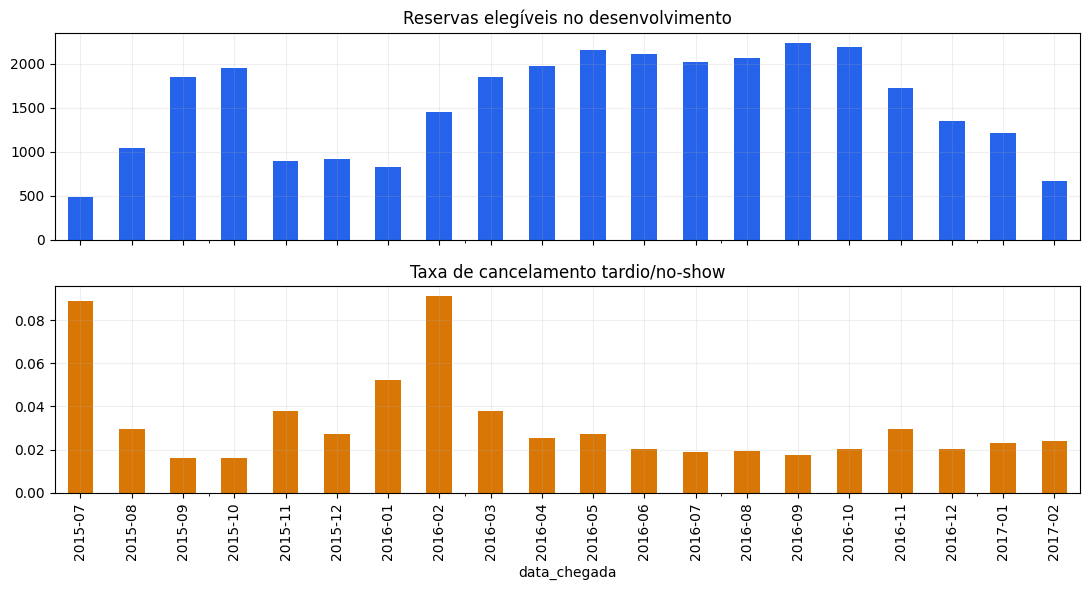

,reservas,taxa
lead_time,,
"(-0.001, 7.0]",5465,0.0446
"(7.0, 30.0]",6634,0.0321
"(30.0, 90.0]",9362,0.0230
"(90.0, 800.0]",9464,0.0212


In [5]:
desenvolvimento = dados.loc[dados.data_chegada <= '2017-02-14']
mensal = desenvolvimento.groupby(desenvolvimento.data_chegada.dt.to_period('M')).agg(
    reservas=('id_linha','size'), taxa=('is_canceled','mean'))
fig, eixos = plt.subplots(2,1,figsize=(11,6),sharex=True)
mensal.reservas.plot.bar(ax=eixos[0], color='#2563eb', title='Reservas elegíveis no desenvolvimento')
mensal.taxa.plot.bar(ax=eixos[1], color='#d97706', title='Taxa de cancelamento tardio/no-show')
plt.tight_layout(); plt.show()
display(desenvolvimento.groupby(pd.cut(desenvolvimento.lead_time,[0,7,30,90,800],include_lowest=True), observed=True).agg(
    reservas=('id_linha','size'), taxa=('is_canceled','mean')))

**Leitura:** diferenças de taxa devem ser lidas junto ao tamanho de cada grupo.
Taxas baixas e instáveis tornam perigoso transformar qualquer diferença em
regra operacional. O corte de 90 dias é uma regra simples predefinida para
comparação; não foi otimizado no teste. Contagem e taxa respondem a perguntas
diferentes: mais cancelamentos pode decorrer de mais reservas.

## 6. Separação cronológica

Treino, calibração de probabilidades, escolha do modelo e teste terão papéis distintos. As lacunas deixam os rótulos amadurecerem.

In [6]:
partes = particoes_a(dados)
separacao = pd.DataFrame([
    {'parte': nome, 'n': len(d), 'inicio': d.data_chegada.min(), 'fim': d.data_chegada.max(),
     'ultimo_rotulo': d.data_rotulo.max(), 'positivos': int(d.is_canceled.sum())}
    for nome,d in partes.items()])
display(separacao)
fora = len(dados) - separacao.n.sum()
print('Fora dos quatro blocos por maturação/lacunas/fim de série:', fora)
salvar_json('auditoria.json', {'filtros': filtros.to_dict('records'), 'n':len(dados),
    'positivos':int(dados.is_canceled.sum()), 'dias':len(serie), 'taxa':dados.is_canceled.mean(),
    'particoes':separacao.to_dict('records'), 'dias_sem_exposicao':int(serie.exposicao.eq(0).sum())})

,parte,n,inicio,fim,ultimo_rotulo,positivos
0,treino,25775,2015-07-01,2016-10-30,2016-11-01,751
1,calibracao,2430,2016-11-01,2016-12-17,2016-12-28,67
2,validacao,1871,2017-01-01,2017-02-14,2017-02-25,44
3,teste,12488,2017-03-01,2017-08-29,2017-09-08,231


Fora dos quatro blocos por maturação/lacunas/fim de série: 1829


**Leitura:** parte dos registros fica fora das quatro funções de avaliação por
desenho, não por limpeza silenciosa. O modelo base fica congelado após o treino;
o calibrador vê somente o bloco seguinte. Essa escolha perde atualização ao
longo do teste, mas evita misturar calibração e seleção. A deriva será medida
por mês. Não usamos divisão aleatória ou validação estratificada ignorando tempo.

<!-- RESULTADOS_A1 -->

## Conclusão da auditoria

A cópia contém **119.390 reservas**. Depois dos filtros explícitos,
restam **44.393 reservas** e **1.155
cancelamentos tardios/no-shows**, taxa de **2,60%**.
A série tem **793 dias**, com 6 dias
sem reserva elegível, e satisfaz os requisitos de tamanho e sazonalidade semanal.

O atraso máximo de conhecimento do rótulo é 15 dias na população auditada.
O recorte reduz a amostra, mas evita usar cancelamentos já conhecidos como
se fossem riscos futuros. A escolha da base está aprovada **para este estudo
retrospectivo sob as hipóteses de reconstrução descritas**, sem afirmar que
dispomos de snapshots operacionais perfeitos.

Há 44 positivos na validação de A: poucas observações para estabelecer a
qualidade de probabilidades extremas. Por isso, qualquer conclusão positiva
de automação exigiria evidência adicional. O próximo notebook mede a perda
das políticas sem alterar esse desenho.